# 06 · Ablation, độ ổn định và giới hạn

> Đọc các run có trong `outputs/runs/` (do `jira-ad experiments` tạo). Notebook **không chạy thêm thực nghiệm** và **không chọn cấu hình theo test**:
> nó cho biết thực nghiệm nào *đã* và *chưa* chạy, so từng yếu tố với baseline kèm độ ổn định theo model seed và nhiễu lấy mẫu, độ phủ OOV và các giới hạn đo được.

**Câu hỏi.**
1. Những ablation trong kế hoạch (có/vô hướng, activity/activity_role, filter_noise/keep_all, q, số chiều, cross-fit, holdout theo thời gian, story) đã chạy chưa, mấy seed?
2. Mỗi yếu tố làm macro AUROC (test) đổi bao nhiêu so với baseline, so với độ ổn định theo seed và nhiễu lấy mẫu?
3. Hai giả thuyết được nêu từ trước (cross-fit đặc trưng train; pooling làm loãng `D_hybrid`) có được ủng hộ trên **validation** theo quy tắc quyết định đã khóa trước khi chạy không?
4. Holdout theo thời gian (train = ca kết thúc sớm nhất) cho kết quả khác holdout ngẫu nhiên không, và nó tách được hai giai đoạn đến đâu?
5. Chuyển tiếp chưa thấy ở train ảnh hưởng điểm thế nào, và cấu hình hiện tại có những giới hạn kỹ thuật nào đo được?

**Quy ước đọc.** Baseline đã khóa trước khi xem test; các thí nghiệm dưới đây là **độ nhạy mang tính khám phá**, không phải xác nhận. Run khác protocol
(khác nội dung core/mutant, khác split hoặc khác cohort) *không* được so trực tiếp với baseline. Riêng mục 4b dùng quy tắc quyết định khóa trước trong `configs/experiments.yaml`.

In [1]:
# Khởi tạo: mở run đã kiểm fingerprint (biến môi trường JIRA_AD_RUN_DIR do `jira-ad notebooks` đặt).
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from jira_ad.analysis import open_run

pd.options.display.float_format = "{:.3f}".format
pd.options.display.max_colwidth = 90
run = open_run()
print(run.header())

run_id      : 20261017T081309Z-930f8a85  (status: completed)
chọn run    : tự động: run hoàn tất mới nhất khớp configs/baseline.yaml hiện tại (đặt JIRA_AD_RUN_DIR để chọn run khác)
config_hash : 930f8a856d4a…  config: configs/experiments.yaml
split_hash  : a3999ae50439…  action_rules: 4a35ef7d0f48…
đầu vào     : dataset/TIeventlogBug.csv sha256=cda16f1c5c4a…; configs/actions.yaml sha256=4a35ef7d0f48…
seeds       : {'split': 42, 'model': 42, 'validation_mutation': 1042, 'test_mutation': 2042}  | cohort: bug  | methods: ['A_stats', 'B_ngrams', 'C_embedding', 'D_hybrid']


In [2]:
import json

import yaml

from jira_ad import plots
from jira_ad.analysis import run_macro_metrics
from jira_ad.pipeline import compare_runs

runs_dir = run.run_dir.parent
comparison = compare_runs(runs_dir)
mine = next(g for g in comparison["groups"] if run.run_id in g["runs"])
print(f"{sum(len(g['runs']) for g in comparison['groups'])} run (mỗi model seed lấy run mới nhất) trong {len(comparison['groups'])} nhóm "
      f"(protocol × cấu hình mô hình); bỏ qua {len(comparison['skipped'])}; protocol của run này: {mine['protocol_id']}.")

36 run (mỗi model seed lấy run mới nhất) trong 12 nhóm (protocol × cấu hình mô hình); bỏ qua 0; protocol của run này: 457baa94321d.


## 1. Run có trong thư mục và khác baseline ở đâu

In [3]:
def flatten(mapping, prefix=""):
    out = {}
    for key, value in mapping.items():
        path = f"{prefix}{key}"
        if isinstance(value, dict):
            out.update(flatten(value, path + "."))
        else:
            out[path] = tuple(value) if isinstance(value, list) else value
    return out

this_config = flatten(yaml.safe_load((run.run_dir / "config.resolved.yaml").read_text(encoding="utf-8")))
IGNORED = {"run.fail_on_existing_output", "run.seed"}
live = {rid for g in comparison["groups"] for rid in g["runs"]}
completed = []
for manifest_path in sorted(runs_dir.glob("*/manifest.json")):
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest.get("status") != "completed" or manifest["run_id"] not in live:
        continue
    config = flatten(yaml.safe_load((manifest_path.parent / "config.resolved.yaml").read_text(encoding="utf-8")))
    diff = {k: config.get(k) for k in set(config) | set(this_config) if config.get(k) != this_config.get(k) and k not in IGNORED}
    completed.append({"run_id": manifest["run_id"], "experiment": manifest.get("experiment", {}).get("name", "(run thủ công)"),
                      "model_seed": manifest["seeds"]["model"],
                      "khác run này ở (trừ seed)": ", ".join(f"{k}={v}" for k, v in sorted(diff.items())) or "(giống hệt)", "_diff": diff})
runs_table = pd.DataFrame(completed)
display(runs_table.drop(columns="_diff"))

,run_id,experiment,model_seed,khác run này ở (trừ seed)
0,20261017T081309Z-930f8a85,baseline,42,(giống hệt)
1,20261017T081312Z-20e50d13,baseline,43,(giống hệt)
2,20261017T081315Z-8bc67d9e,baseline,44,(giống hệt)
3,20261017T081318Z-aeba7e1c,undirected_walk,42,graph.directed=False
4,20261017T081322Z-d5db01eb,undirected_walk,43,graph.directed=False
5,20261017T081326Z-0cfa5389,undirected_walk,44,graph.directed=False
6,20261017T081330Z-1baf5ac7,activity_role_nodes,42,graph.encoding=activity_role
7,20261017T081335Z-3e4d9203,activity_role_nodes,43,graph.encoding=activity_role
8,20261017T081340Z-6f91ee37,activity_role_nodes,44,graph.encoding=activity_role
9,20261017T081346Z-c3324bdd,keep_all_noise,42,preprocess.noise_policy=keep_all


## 2. Kế hoạch ablation đã/chưa chạy

In [4]:
PLANNED = [
    ("Có hướng → vô hướng (walk)", {"graph.directed": False}),
    ("Nút activity → activity_role", {"graph.encoding": "activity_role"}),
    ("filter_noise → keep_all", {"preprocess.noise_policy": "keep_all"}),
    ("q = 0,5 (p = 1)", {"walk.q": 0.5}),
    ("q = 2 (p = 1)", {"walk.q": 2.0}),
    ("số chiều = 32", {"embedding.dimensions": 32}),
    ("số chiều = 4 (giả thuyết 2)", {"embedding.dimensions": 4}),
    ("số chiều = 8 (giả thuyết 2)", {"embedding.dimensions": 8}),
    ("cross-fit 5 fold trên train (giả thuyết 1)", {"features.cross_fit_folds": 5}),
    ("holdout theo thời gian (protocol riêng)", {"split.strategy": "temporal"}),
    ("cohort story (protocol riêng)", {"data.cohort": "story"}),
]
rows = []
for name, change in PLANNED:
    match = [r for r in completed if r["_diff"] == change]
    seeds = sorted({r["model_seed"] for r in match})
    rows.append({"thực nghiệm kế hoạch": name, "đổi so với run này": str(change),
                 "trạng thái": f"đã chạy ({len(seeds)} seed)" if seeds else "CHƯA chạy"})
n_base_seeds = len({r["model_seed"] for r in completed if r["_diff"] == {}})
rows.append({"thực nghiệm kế hoạch": "độ ổn định theo model seed", "đổi so với run này": "run.seed 42/43/44",
             "trạng thái": f"đã chạy ({n_base_seeds} seed)" if n_base_seeds > 1 else "CHƯA chạy (chỉ 1 seed)"})
ablations = pd.DataFrame(rows)
run.save_table(ablations, "nb06_planned_ablations")
display(ablations)
not_run = int(ablations["trạng thái"].str.startswith("CHƯA").sum())
display(Markdown(
    f"**{len(ablations) - not_run}/{len(ablations)}** thực nghiệm trong kế hoạch đã có run; **{not_run}** chưa chạy nên chưa có kết luận về chúng. "
    "Mỗi ablation đổi *từng yếu tố một* so với baseline (không chạy tích Descartes)."
))

,thực nghiệm kế hoạch,đổi so với run này,trạng thái
0,Có hướng → vô hướng (walk),{'graph.directed': False},đã chạy (3 seed)
1,Nút activity → activity_role,{'graph.encoding': 'activity_role'},đã chạy (3 seed)
2,filter_noise → keep_all,{'preprocess.noise_policy': 'keep_all'},đã chạy (3 seed)
3,"q = 0,5 (p = 1)",{'walk.q': 0.5},đã chạy (3 seed)
4,q = 2 (p = 1),{'walk.q': 2.0},đã chạy (3 seed)
5,số chiều = 32,{'embedding.dimensions': 32},đã chạy (3 seed)
6,số chiều = 4 (giả thuyết 2),{'embedding.dimensions': 4},đã chạy (3 seed)
7,số chiều = 8 (giả thuyết 2),{'embedding.dimensions': 8},đã chạy (3 seed)
8,cross-fit 5 fold trên train (giả thuyết 1),{'features.cross_fit_folds': 5},đã chạy (3 seed)
9,holdout theo thời gian (protocol riêng),{'split.strategy': 'temporal'},đã chạy (3 seed)


**12/12** thực nghiệm trong kế hoạch đã có run; **0** chưa chạy nên chưa có kết luận về chúng. Mỗi ablation đổi *từng yếu tố một* so với baseline (không chạy tích Descartes).

## 3. Độ nhạy: macro AUROC (test) theo thí nghiệm

In [5]:
def macro_summary(group):
    macro = run_macro_metrics(runs_dir, group["runs"], split="test")
    stats = macro.groupby("method").macro_auroc.agg(mean="mean", std="std", n_seeds="count")
    return stats.reset_index().assign(experiment=group["experiments"][0], protocol=group["protocol_id"])

summary = pd.concat([macro_summary(g) for g in comparison["groups"]], ignore_index=True)
summary["cùng protocol với run này"] = summary.protocol == mine["protocol_id"]
baseline_name = mine["experiments"][0]
base_means = summary[summary.experiment == baseline_name].set_index("method")["mean"]
summary["Δ so với baseline"] = summary.apply(
    lambda r: r["mean"] - base_means[r.method] if r["cùng protocol với run này"] else np.nan, axis=1)
run.save_table(summary, "nb06_ablation_summary")
comparable = summary[summary["cùng protocol với run này"]]
display(Markdown("**Cùng protocol với run này** (cùng ca, split, bộ mutant; chỉ khác một yếu tố của mô hình):"))
display(comparable.pivot(index="experiment", columns="method", values="mean").reindex(
    list(dict.fromkeys(comparable.experiment)))[run.methods])
display(comparable.pivot(index="experiment", columns="method", values="Δ so với baseline").reindex(
    list(dict.fromkeys(comparable.experiment)))[run.methods])

**Cùng protocol với run này** (cùng ca, split, bộ mutant; chỉ khác một yếu tố của mô hình):

method,A_stats,B_ngrams,C_embedding,D_hybrid
experiment,,,,
baseline,0.531,0.513,0.535,0.544
undirected_walk,0.531,0.513,0.527,0.533
activity_role_nodes,0.551,0.504,0.527,0.541
q_half,0.531,0.513,0.537,0.547
q_double,0.531,0.513,0.529,0.528
dim_32,0.531,0.513,0.531,0.538
cross_fit_5,0.527,0.510,0.535,0.536
dim_4,0.531,0.513,0.518,0.532
dim_8,0.531,0.513,0.534,0.537


method,A_stats,B_ngrams,C_embedding,D_hybrid
experiment,,,,
baseline,0.000,0.000,0.000,0.000
undirected_walk,0.000,0.000,-0.008,-0.010
activity_role_nodes,0.019,-0.009,-0.008,-0.002
q_half,0.000,0.000,0.002,0.003
q_double,0.000,0.000,-0.006,-0.016
dim_32,0.000,0.000,-0.004,-0.006
cross_fit_5,-0.004,-0.003,-0.000,-0.008
dim_4,0.000,0.000,-0.017,-0.012
dim_8,0.000,0.000,-0.001,-0.006


**Khác protocol** — số liệu *không* so trực tiếp được với baseline (khác dữ liệu core/mutant hoặc khác cohort):

method,A_stats,B_ngrams,C_embedding,D_hybrid
experiment,,,,
keep_all_noise,0.534,0.516,0.529,0.529
story_cohort,0.636,0.528,0.552,0.591
temporal_holdout,0.560,0.509,0.546,0.565


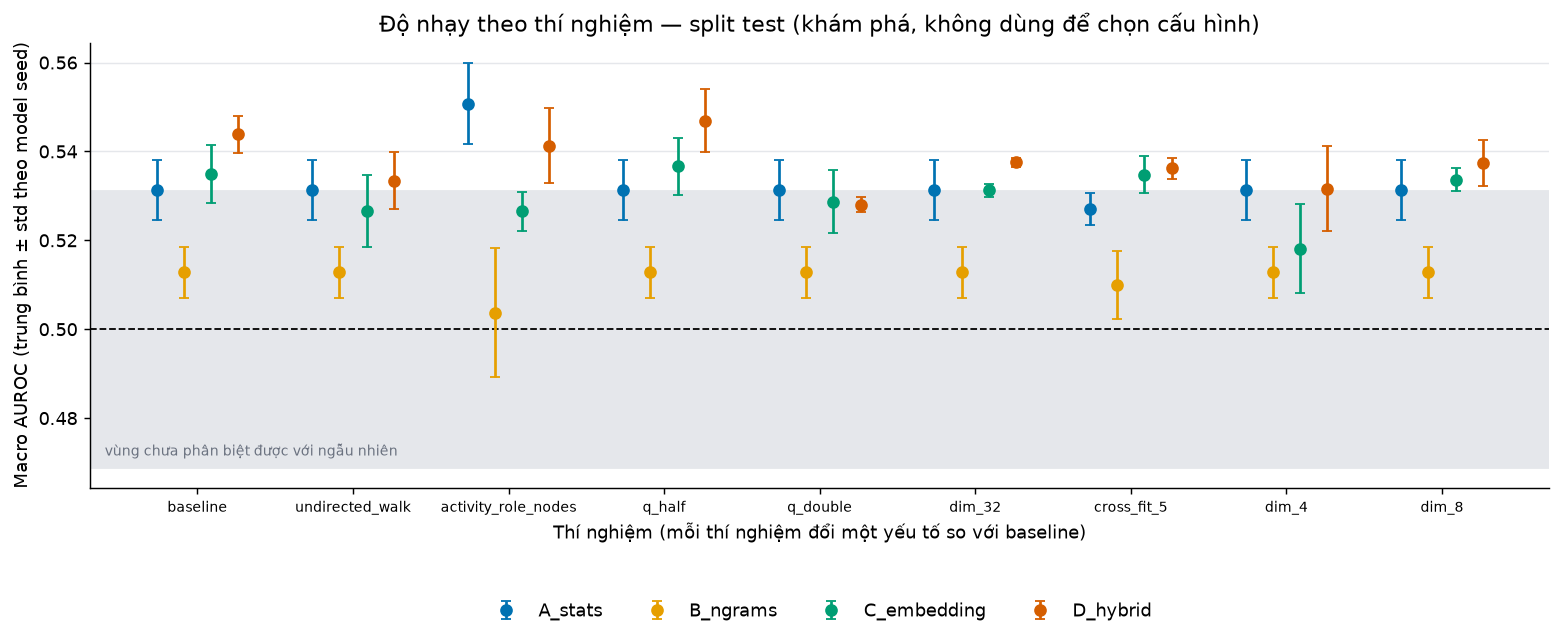

Dải xám: ±1,96 × SD của AUROC dưới giả thuyết không *ghép cặp* (hoán vị trong cặp, tính theo từng loại nên bảo thủ cho macro) ≈ ±0.031 quanh 0,5 (n = 31 cặp). Thanh lỗi là độ lệch chuẩn theo model seed (độ ổn định của bước học).

**Δ macro AUROC so với baseline (test, khám phá)**, khoảng bootstrap ghép cặp theo parent 95% (chưa hiệu chỉnh đa so sánh); trung bình qua các model seed:

method,A_stats,B_ngrams,C_embedding,D_hybrid
experiment,,,,
undirected_walk,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.008 [-0.021, +0.005]","-0.010 [-0.025, +0.004]"
activity_role_nodes,"+0.019 [-0.005, +0.049]","-0.009 [-0.035, +0.013]","-0.008 [-0.024, +0.010]","-0.002 [-0.019, +0.018]"
q_half,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","+0.002 [-0.009, +0.012]","+0.003 [-0.011, +0.018]"
q_double,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.006 [-0.017, +0.005]","-0.016 [-0.029, -0.004]"
dim_32,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.004 [-0.014, +0.006]","-0.006 [-0.019, +0.006]"
cross_fit_5,"-0.004 [-0.028, +0.019]","-0.003 [-0.009, +0.003]","-0.000 [-0.006, +0.005]","-0.008 [-0.022, +0.003]"
dim_4,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.017 [-0.035, +0.000]","-0.012 [-0.033, +0.006]"
dim_8,"+0.000 [+0.000, +0.000]","+0.000 [+0.000, +0.000]","-0.001 [-0.015, +0.013]","-0.006 [-0.023, +0.009]"


In [6]:
other = summary[~summary["cùng protocol với run này"]]
if len(other):
    display(Markdown("**Khác protocol** — số liệu *không* so trực tiếp được với baseline (khác dữ liệu core/mutant hoặc khác cohort):"))
    display(other.pivot(index="experiment", columns="method", values="mean")[run.methods])

from jira_ad.analysis import ablation_vs_baseline

ev = run.cfg.evaluation
group_runs = {g["experiments"][0]: g["runs"] for g in comparison["groups"]}
metrics_test = run.read_csv("metrics_by_type.csv").query("split == 'test'")
n_pairs = int(metrics_test.n_mutant.min())
independent_se = float(np.sqrt((2 * n_pairs + 1) / (12 * n_pairs * n_pairs)))   # hai mẫu độc lập: quá rộng cho dữ liệu ghép cặp
chance_file = run.run_dir / "chance_test.csv"
if chance_file.is_file():
    chance_sd = float(pd.read_csv(chance_file).query("split == 'test'").null_sd.mean())   # SD của AUROC dưới H0 ghép cặp, theo từng loại
    band_note = "±1,96 × SD của AUROC dưới giả thuyết không *ghép cặp* (hoán vị trong cặp, tính theo từng loại nên bảo thủ cho macro)"
else:
    chance_sd = independent_se
    band_note = "±1,96 × SE công thức hai mẫu độc lập (quá rộng cho dữ liệu ghép cặp; run này chưa có chance_test.csv)"
fig = plots.plot_ablation(comparable.rename(columns={"mean": "mean", "std": "std"}), chance_halfwidth=1.96 * chance_sd)
_ = run.show(fig, "nb06_ablation", comparable[["experiment", "method", "mean", "std", "n_seeds", "Δ so với baseline"]])
display(Markdown(
    f"Dải xám: {band_note} ≈ ±{1.96 * chance_sd:.3f} quanh 0,5 (n = {n_pairs} cặp). Thanh lỗi là độ lệch chuẩn theo model seed (độ ổn định của bước học)."
))

same = [n for n in dict.fromkeys(comparable.experiment) if n != baseline_name]
sens = None
if same:
    sens = ablation_vs_baseline(
        runs_dir, {n: group_runs[n] for n in [baseline_name, *same]}, baseline=baseline_name, split="test",
        n_resamples=ev.bootstrap_resamples, seed=ev.bootstrap_seed, confidence=0.95)
    run.save_table(sens, "nb06_sensitivity_test")
    macro_sens = sens[(sens.scope == "macro") & (sens.metric == "auroc")]
    text = macro_sens.assign(ô=lambda f: [f"{e:+.3f} [{lo:+.3f}, {hi:+.3f}]" for e, lo, hi in zip(f.estimate, f.ci_low, f.ci_high)])
    display(Markdown("**Δ macro AUROC so với baseline (test, khám phá)**, khoảng bootstrap ghép cặp theo parent 95% (chưa hiệu chỉnh đa so sánh); trung bình qua các model seed:"))
    display(text.pivot(index="experiment", columns="method", values="ô").reindex(same)[run.methods])

## 4. Độ ổn định theo model seed (nhóm của run này)

In [7]:
macro = run_macro_metrics(runs_dir, mine["runs"], split="test")
seed_of = {rid: json.loads((runs_dir / rid / "manifest.json").read_text(encoding="utf-8"))["seeds"]["model"] for rid in mine["runs"]}
macro["model_seed"] = macro.run_id.map(seed_of)
per_seed = macro.pivot(index="method", columns="model_seed", values="macro_auroc").reindex(run.methods)
if per_seed.shape[1] < 2:
    display(Markdown(
        f"Nhóm của run này chỉ có **{per_seed.shape[1]}** model seed ⇒ **chưa đo được** độ ổn định theo seed. "
        "Chạy `uv run jira-ad experiments --config configs/experiments.yaml --only baseline` để có seed 42/43/44."
    ))
else:
    stability = per_seed.assign(mean=per_seed.mean(axis=1), std=per_seed.std(axis=1, ddof=1),
                                range=per_seed.max(axis=1) - per_seed.min(axis=1))
    run.save_table(stability.reset_index(), "nb06_seed_stability")
    display(stability)
    display(Markdown(
        f"Std theo seed của macro AUROC: **{stability['std'].min():.3f}–{stability['std'].max():.3f}** qua {per_seed.shape[1]} model seed "
        "(cùng split, cùng mutant). Đây là độ ổn định của bước học, **không** là khoảng tin cậy quần thể và không phải nhiều mẫu dữ liệu độc lập."
    ))

model_seed,42,43,44,mean,std,range
method,,,,,,
A_stats,0.527,0.539,0.527,0.531,0.007,0.012
B_ngrams,0.519,0.512,0.507,0.513,0.006,0.011
C_embedding,0.528,0.540,0.537,0.535,0.006,0.012
D_hybrid,0.545,0.539,0.547,0.544,0.004,0.008


Std theo seed của macro AUROC: **0.004–0.007** qua 3 model seed (cùng split, cùng mutant). Đây là độ ổn định của bước học, **không** là khoảng tin cậy quần thể và không phải nhiều mẫu dữ liệu độc lập.

## 4b. Kiểm hai giả thuyết bằng quy tắc quyết định khóa trước

Khối `decision` của `configs/experiments.yaml` được khóa **trước khi chạy** `cross_fit_5`, `dim_4`, `dim_8`. Chỉ số chính là macro AUROC của phương pháp chính trên **validation**, trung bình qua các model seed.
Một thí nghiệm chỉ là *ứng viên cải thiện* nếu khoảng bootstrap theo parent của (thí nghiệm − baseline) nằm hoàn toàn trên 0, ở mức tin cậy đã chia theo số so sánh (Bonferroni).
Dù kết quả thế nào, baseline vẫn là cấu hình ghi nhận. Test chỉ được xem **sau** phán quyết và chỉ để mô tả.

In [8]:
from jira_ad.analysis import ablation_vs_baseline
from jira_ad.experiments import load_plan

plan_path = run.project_root / "configs" / "experiments.yaml"
group_runs = {g["experiments"][0]: g["runs"] for g in comparison["groups"]}
rule = load_plan(plan_path).decision if plan_path.is_file() else None
needed = ["baseline", *(rule.comparisons if rule else [])]
missing = [n for n in needed if n not in group_runs]
verdicts = None
if rule is None:
    display(Markdown("Không có khối `decision` trong `configs/experiments.yaml` (hoặc không có file) ⇒ không có quy tắc quyết định khóa trước để áp dụng."))
elif missing:
    display(Markdown(f"Thiếu run của {missing} ⇒ chưa kiểm được. Chạy: `uv run jira-ad experiments --config configs/experiments.yaml`."))
else:
    ev = run.cfg.evaluation
    selection = ablation_vs_baseline(
        runs_dir, {n: group_runs[n] for n in needed}, baseline="baseline", split=rule.selection_split,
        n_resamples=ev.bootstrap_resamples, seed=ev.bootstrap_seed, confidence=rule.confidence)
    run.save_table(selection, "nb06_selection_validation")
    primary = selection[(selection.scope == "macro") & (selection.metric == "auroc")
                        & (selection.method == rule.primary_method)].copy()
    primary["phán quyết (validation)"] = np.where(primary.ci_low > 0, "ứng viên cải thiện", "không có bằng chứng")
    verdicts = primary.set_index("experiment").reindex(list(rule.comparisons))
    display(Markdown(
        f"**Phương pháp chính `{rule.primary_method}`, macro AUROC trên {rule.selection_split}** — khoảng bootstrap {rule.confidence:.2%} "
        f"(= 1 − {rule.family_alpha}/{len(rule.comparisons)}), trung bình {int(primary.n_seeds.iloc[0])} model seed, {int(primary.n_parents.iloc[0])} parent:"))
    display(verdicts[["baseline_estimate", "experiment_estimate", "estimate", "ci_low", "ci_high", "prob_positive", "phán quyết (validation)"]])
    others = selection[(selection.scope == "macro") & (selection.metric == "auroc") & (selection.method != rule.primary_method)]
    display(Markdown("Các phương pháp khác (chỉ mô tả, **không** dùng để quyết định). `A_stats`/`B_ngrams` không dùng embedding nên đổi số chiều cho Δ đúng 0 (kiểm chéo tính tất định):"))
    display(others.pivot(index="experiment", columns="method", values="estimate").reindex(list(rule.comparisons)))

**Phương pháp chính `D_hybrid`, macro AUROC trên validation** — khoảng bootstrap 98.33% (= 1 − 0.05/3), trung bình 3 model seed, 33 parent:

,baseline_estimate,experiment_estimate,estimate,ci_low,ci_high,prob_positive,phán quyết (validation)
experiment,,,,,,,
cross_fit_5,0.547,0.535,-0.012,-0.032,0.003,0.021,không có bằng chứng
dim_4,0.547,0.529,-0.017,-0.053,0.017,0.112,không có bằng chứng
dim_8,0.547,0.546,-0.001,-0.029,0.023,0.480,không có bằng chứng


Các phương pháp khác (chỉ mô tả, **không** dùng để quyết định). `A_stats`/`B_ngrams` không dùng embedding nên đổi số chiều cho Δ đúng 0 (kiểm chéo tính tất định):

method,A_stats,B_ngrams,C_embedding
experiment,,,
cross_fit_5,-0.014,-0.010,0.002
dim_4,0.000,0.000,-0.031
dim_8,0.000,0.000,0.004


In [9]:
mechanism = None
if verdicts is not None:
    rows = []
    for name in needed:
        rid = group_runs[name][0]
        for method in dict.fromkeys(["A_stats", rule.primary_method]):
            if method not in run.methods:
                continue
            meta = json.loads((runs_dir / rid / "models" / method / "fit_metadata.json").read_text(encoding="utf-8"))
            rows.append({"thí nghiệm": name, "method": method, "n_features": meta["n_features"],
                         "feature hằng trên train": meta["n_constant_features"],
                         "tên (tối đa 50)": ", ".join(meta["constant_feature_names"])})
    mechanism = pd.DataFrame(rows)
    run.save_table(mechanism, "nb06_mechanism")
    display(Markdown("**Cơ chế:** cột hằng trên train (Isolation Forest không chia được theo chúng). Cross-fit chỉ có ý nghĩa nếu nó làm các cột `unseen_*` hết hằng:"))
    display(mechanism)

**Cơ chế:** cột hằng trên train (Isolation Forest không chia được theo chúng). Cross-fit chỉ có ý nghĩa nếu nó làm các cột `unseen_*` hết hằng:

,thí nghiệm,method,n_features,feature hằng trên train,tên (tối đa 50)
0,baseline,A_stats,10,2,"unseen_node_ratio, unseen_transition_ratio"
1,baseline,D_hybrid,42,3,"emb_max_12, unseen_node_ratio, unseen_transition_ratio"
2,cross_fit_5,A_stats,10,0,
3,cross_fit_5,D_hybrid,42,1,emb_max_12
4,dim_4,A_stats,10,2,"unseen_node_ratio, unseen_transition_ratio"
5,dim_4,D_hybrid,18,2,"unseen_node_ratio, unseen_transition_ratio"
6,dim_8,A_stats,10,2,"unseen_node_ratio, unseen_transition_ratio"
7,dim_8,D_hybrid,26,2,"unseen_node_ratio, unseen_transition_ratio"


In [10]:
exploratory = None
if verdicts is not None:
    exploratory = ablation_vs_baseline(
        runs_dir, {n: group_runs[n] for n in needed}, baseline="baseline", split="test",
        n_resamples=ev.bootstrap_resamples, seed=ev.bootstrap_seed, confidence=rule.confidence)
    run.save_table(exploratory, "nb06_exploratory_test")
    view = exploratory[(exploratory.scope == "macro") & (exploratory.metric == "auroc")
                       & (exploratory.method == rule.primary_method)].set_index("experiment").reindex(list(rule.comparisons))
    display(Markdown(
        f"**KHÁM PHÁ — xem sau phán quyết trên validation, không dùng để chọn cấu hình.** `{rule.primary_method}`, macro AUROC trên test "
        f"(cùng cách tính, {int(view.n_parents.iloc[0])} parent):"))
    display(view[["baseline_estimate", "experiment_estimate", "estimate", "ci_low", "ci_high"]])

**KHÁM PHÁ — xem sau phán quyết trên validation, không dùng để chọn cấu hình.** `D_hybrid`, macro AUROC trên test (cùng cách tính, 31 parent):

,baseline_estimate,experiment_estimate,estimate,ci_low,ci_high
experiment,,,,,
cross_fit_5,0.544,0.536,-0.008,-0.027,0.005
dim_4,0.544,0.532,-0.012,-0.038,0.011
dim_8,0.544,0.537,-0.006,-0.026,0.012


## 4c. Holdout theo thời gian (protocol riêng)

Train = 60% ca **kết thúc sớm nhất**, validation = 20% kế tiếp, test = 20% muộn nhất (spec §5.1, phần mở rộng). Đây là một protocol khác (tập ca held-out, mutant và số train khác baseline),
nên số liệu **không** được trừ trực tiếp với baseline; chỉ đặt cạnh nhau. Ca held-out có thể đã *bắt đầu* trước khi giai đoạn train kết thúc: không rò rỉ lịch sử train vào tương lai,
nhưng cho thấy hai giai đoạn không tách hẳn nhau.

In [11]:
temporal = group_runs.get("temporal_holdout")
temporal_summary = None
if temporal is None:
    display(Markdown("Chưa có run `temporal_holdout`. Chạy: `uv run jira-ad experiments --config configs/experiments.yaml --only temporal_holdout`."))
else:
    audit = json.loads((runs_dir / temporal[0] / "preprocess_audit.json").read_text(encoding="utf-8"))["split"]
    report = audit["temporal"]
    split_table = pd.DataFrame(report["by_split"]).T
    split_table["DONE"] = [audit["terminal_status_by_split"][s].get("DONE", 0) for s in split_table.index]
    split_table["Rejected"] = [audit["terminal_status_by_split"][s].get("Rejected", 0) for s in split_table.index]
    run.save_table(split_table.reset_index(names="split"), "nb06_temporal_split")
    display(split_table)
    display(Markdown(
        f"**{report['n_heldout_started_before_train_end']}/{report['n_heldout']}** ca held-out đã bắt đầu trước khi giai đoạn train kết thúc ({report['train_end_utc']}); "
        "ca sống lâu nên hai giai đoạn chồng lên nhau. Hòa thời điểm ở ranh giới: "
        f"train/validation = {report['train_validation_boundary_tie']}, validation/test = {report['validation_test_boundary_tie']}."))
    macro_t = run_macro_metrics(runs_dir, temporal, split="test").groupby("method").macro_auroc.agg(["mean", "std"])
    macro_b = run_macro_metrics(runs_dir, group_runs["baseline"], split="test").groupby("method").macro_auroc.agg(["mean", "std"])
    intervals_t = pd.read_csv(runs_dir / temporal[0] / "bootstrap_intervals.csv") if (runs_dir / temporal[0] / "bootstrap_intervals.csv").is_file() else None
    temporal_summary = pd.DataFrame({
        "temporal: macro AUROC (test)": macro_t["mean"], "temporal: std theo seed": macro_t["std"],
        "ngẫu nhiên (baseline): macro AUROC (test)": macro_b["mean"]}).reindex(run.methods)
    if intervals_t is not None:
        first = intervals_t[(intervals_t.split == "test") & (intervals_t.scope == "macro") & (intervals_t.metric == "auroc")].set_index("method")
        temporal_summary["temporal: khoảng bootstrap (1 seed)"] = [f"[{first.ci_low[m]:.3f}, {first.ci_high[m]:.3f}]" for m in run.methods]
    run.save_table(temporal_summary.reset_index(), "nb06_temporal_vs_random")
    display(Markdown("Khác protocol — đặt cạnh nhau, **không** trừ:"))
    display(temporal_summary)

,n,first_terminal_utc,last_terminal_utc,DONE,Rejected
train,97,2021-06-30T11:08:48+00:00,2022-01-25T12:34:41+00:00,50,47
validation,32,2022-01-27T06:47:46+00:00,2022-04-04T09:39:20+00:00,18,14
test,32,2022-04-05T09:39:22+00:00,2022-06-27T08:58:53+00:00,15,17


**29/64** ca held-out đã bắt đầu trước khi giai đoạn train kết thúc (2022-01-25T12:34:41+00:00); ca sống lâu nên hai giai đoạn chồng lên nhau. Hòa thời điểm ở ranh giới: train/validation = False, validation/test = False.

Khác protocol — đặt cạnh nhau, **không** trừ:

,temporal: macro AUROC (test),temporal: std theo seed,ngẫu nhiên (baseline): macro AUROC (test),temporal: khoảng bootstrap (1 seed)
method,,,,
A_stats,0.560,0.007,0.531,"[0.531, 0.593]"
B_ngrams,0.509,0.014,0.513,"[0.461, 0.525]"
C_embedding,0.546,0.005,0.535,"[0.524, 0.590]"
D_hybrid,0.565,0.006,0.544,"[0.533, 0.616]"


## 5. Độ phủ OOV và điểm

In [12]:
from scipy.stats import spearmanr

originals = run.read_parquet("scores/originals.parquet")
test = originals[originals.split == "test"]
rows = []
for method, part in test.groupby("method"):
    rho = spearmanr(part.unseen_transition_ratio, part.anomaly_score).statistic if part.unseen_transition_ratio.nunique() > 1 else float("nan")
    rows.append({"method": method, "n": len(part), "unseen_transition_ratio trung bình": part.unseen_transition_ratio.mean(),
                 "Spearman(unseen_transition_ratio, điểm)": rho})
oov = pd.DataFrame(rows).set_index("method").reindex(run.methods)
run.save_table(oov.reset_index(), "nb06_oov")
oov

,n,unseen_transition_ratio trung bình,"Spearman(unseen_transition_ratio, điểm)"
method,,,
A_stats,31,0.095,-0.056
B_ngrams,31,0.095,0.359
C_embedding,31,0.095,0.285
D_hybrid,31,0.095,0.184


## 6. Giới hạn kỹ thuật đo được

In [13]:
meta = {m: run.read_json(f"models/{m}/fit_metadata.json") for m in run.methods}
limits = pd.DataFrame([{
    "method": m, "n_features": meta[m]["n_features"], "n_train": meta[m]["n_train"],
    "feature hằng trên train": meta[m]["n_constant_features"],
    "chiều/mẫu train": meta[m]["n_features"] / meta[m]["n_train"],
} for m in run.methods]).set_index("method")
run.save_table(limits.reset_index(), "nb06_limits")
display(limits)
constant = meta["A_stats"]["constant_feature_names"]
display(Markdown(
    f"- Đặc trưng hằng trên train của `A_stats`: **{constant}**. Đồ thị được fit từ chính các trace train nên trên train mọi nút/chuyển tiếp đều ‘đã thấy’ "
    "(fit→transform in-sample); Isolation Forest không chia được theo feature hằng nên các cột `unseen_*` không đóng góp khi fit, dù chúng khác 0 ở validation/test.\n"
    f"- `B_ngrams` có {limits.n_features['B_ngrams']} chiều cho {limits.n_train['B_ngrams']} trace train (chiều/mẫu = {limits['chiều/mẫu train']['B_ngrams']:.1f}); các cột n-gram rất thưa.\n"
    "- Mỗi mutant chỉ là một chỉnh sửa cấu trúc có kiểm soát; không chứng minh vi phạm nghiệp vụ."
))

,n_features,n_train,feature hằng trên train,chiều/mẫu train
method,,,,
A_stats,10,97,2,0.103
B_ngrams,442,97,2,4.557
C_embedding,33,97,2,0.340
D_hybrid,42,97,3,0.433


- Đặc trưng hằng trên train của `A_stats`: **['unseen_node_ratio', 'unseen_transition_ratio']**. Đồ thị được fit từ chính các trace train nên trên train mọi nút/chuyển tiếp đều ‘đã thấy’ (fit→transform in-sample); Isolation Forest không chia được theo feature hằng nên các cột `unseen_*` không đóng góp khi fit, dù chúng khác 0 ở validation/test.
- `B_ngrams` có 442 chiều cho 97 trace train (chiều/mẫu = 4.6); các cột n-gram rất thưa.
- Mỗi mutant chỉ là một chỉnh sửa cấu trúc có kiểm soát; không chứng minh vi phạm nghiệp vụ.

## Nhận xét (sinh từ số liệu của run này)

In [14]:
done = len(ablations) - not_run
lines = [
    f"- **Phạm vi thực nghiệm:** {done}/{len(ablations)} mục trong kế hoạch đã có run; còn {not_run} mục chưa chạy nên không có kết luận.",
]
if sens is not None:
    cells = sens[(sens.scope == "macro") & (sens.metric == "auroc")]
    outside = cells[(cells.ci_low > 0) | (cells.ci_high < 0)]
    lines.append(
        f"- **Độ nhạy (test, khám phá, bootstrap ghép cặp 95% chưa hiệu chỉnh đa so sánh):** {len(cells)} ô (thí nghiệm × phương pháp), |Δ macro AUROC| lớn nhất {cells.estimate.abs().max():.3f}; "
        + (f"{len(outside)} ô có khoảng không chứa 0: " + ", ".join(f"{r.experiment}/{r.method} ({r.estimate:+.3f})" for r in outside.itertuples()) + "."
           if len(outside) else "mọi khoảng đều chứa 0."))
else:
    lines.append("- **Độ nhạy:** chưa có ablation cùng protocol nào để so.")
if verdicts is not None:
    for name, r in verdicts.iterrows():
        lines.append(
            f"- **Quy tắc khóa trước, `{name}`** ({rule.primary_method}, {rule.selection_split}): Δ macro AUROC = {r['estimate']:+.4f} "
            f"[{r['ci_low']:+.4f}, {r['ci_high']:+.4f}] ⇒ **{r['phán quyết (validation)']}**.")
    n_candidate = int((verdicts["phán quyết (validation)"] == "ứng viên cải thiện").sum())
    lines.append(
        f"- **Tổng hợp giả thuyết:** {n_candidate}/{len(verdicts)} so sánh là ứng viên cải thiện; baseline vẫn là cấu hình ghi nhận."
        + (" Không có bằng chứng ủng hộ cross-fit hay giảm số chiều." if n_candidate == 0 else " Cần xác nhận thêm trước khi đổi cấu hình."))
if mechanism is not None:
    base_rows = mechanism[mechanism["thí nghiệm"] == "baseline"].set_index("method")["feature hằng trên train"]
    cf_rows = mechanism[mechanism["thí nghiệm"] == "cross_fit_5"].set_index("method")["feature hằng trên train"] if (mechanism["thí nghiệm"] == "cross_fit_5").any() else None
    if cf_rows is not None:
        lines.append("- **Cơ chế cross-fit:** số cột hằng trên train " + ", ".join(
            f"{m}: {int(base_rows[m])} → {int(cf_rows[m])}" for m in base_rows.index)
            + " — tiền đề của giả thuyết 1 (cột `unseen_*` có phương sai khi fit) đã được thỏa, nên việc không cải thiện không do cross-fit không chạy.")
if temporal_summary is not None:
    gap = (temporal_summary["temporal: macro AUROC (test)"] - temporal_summary["ngẫu nhiên (baseline): macro AUROC (test)"])
    lines.append(
        f"- **Holdout theo thời gian:** {report['n_heldout_started_before_train_end']}/{report['n_heldout']} ca held-out đã bắt đầu trước khi train kết thúc; macro AUROC (test) "
        + ", ".join(f"{m} {temporal_summary['temporal: macro AUROC (test)'][m]:.3f}" for m in run.methods)
        + f" (chênh với holdout ngẫu nhiên {gap.min():+.3f} đến {gap.max():+.3f}; khác protocol nên chỉ để tham khảo).")
lines += [
    f"- **Seed:** " + ("chưa đo được độ ổn định theo seed (1 seed)." if per_seed.shape[1] < 2
                       else f"std theo seed {stability['std'].min():.3f}–{stability['std'].max():.3f} qua {per_seed.shape[1]} seed."),
    f"- **OOV:** `unseen_transition_ratio` trung bình trên test = {test[test.method == run.methods[0]].unseen_transition_ratio.mean():.3f}.",
    f"- **Cấu hình hiện tại:** tổng {int(limits['feature hằng trên train'].sum())} feature hằng trên train gộp các phương pháp; B_ngrams có {limits['chiều/mẫu train']['B_ngrams']:.1f} chiều/mẫu.",
]
display(Markdown("\n".join(lines)))

- **Phạm vi thực nghiệm:** 12/12 mục trong kế hoạch đã có run; còn 0 mục chưa chạy nên không có kết luận.
- **Độ nhạy (test, khám phá, bootstrap ghép cặp 95% chưa hiệu chỉnh đa so sánh):** 32 ô (thí nghiệm × phương pháp), |Δ macro AUROC| lớn nhất 0.019; 1 ô có khoảng không chứa 0: q_double/D_hybrid (-0.016).
- **Quy tắc khóa trước, `cross_fit_5`** (D_hybrid, validation): Δ macro AUROC = -0.0122 [-0.0322, +0.0027] ⇒ **không có bằng chứng**.
- **Quy tắc khóa trước, `dim_4`** (D_hybrid, validation): Δ macro AUROC = -0.0174 [-0.0525, +0.0172] ⇒ **không có bằng chứng**.
- **Quy tắc khóa trước, `dim_8`** (D_hybrid, validation): Δ macro AUROC = -0.0010 [-0.0291, +0.0227] ⇒ **không có bằng chứng**.
- **Tổng hợp giả thuyết:** 0/3 so sánh là ứng viên cải thiện; baseline vẫn là cấu hình ghi nhận. Không có bằng chứng ủng hộ cross-fit hay giảm số chiều.
- **Cơ chế cross-fit:** số cột hằng trên train A_stats: 2 → 0, D_hybrid: 3 → 1 — tiền đề của giả thuyết 1 (cột `unseen_*` có phương sai khi fit) đã được thỏa, nên việc không cải thiện không do cross-fit không chạy.
- **Holdout theo thời gian:** 29/64 ca held-out đã bắt đầu trước khi train kết thúc; macro AUROC (test) A_stats 0.560, B_ngrams 0.509, C_embedding 0.546, D_hybrid 0.565 (chênh với holdout ngẫu nhiên -0.003 đến +0.029; khác protocol nên chỉ để tham khảo).
- **Seed:** std theo seed 0.004–0.007 qua 3 seed.
- **OOV:** `unseen_transition_ratio` trung bình trên test = 0.095.
- **Cấu hình hiện tại:** tổng 9 feature hằng trên train gộp các phương pháp; B_ngrams có 4.6 chiều/mẫu.

## Giả thuyết và giới hạn

- Hai giả thuyết nêu từ trước (cross-fit đặc trưng train; pooling làm loãng `D_hybrid`) được kiểm ở mục 4b theo quy tắc khóa trước; kết luận nằm ở phần Nhận xét (sinh từ số liệu), không cố định ở đây.
- **Chưa kiểm:** mô hình riêng theo nhánh DONE/Rejected (cỡ mẫu mỗi nhánh còn nhỏ hơn); cross-fit cho **embedding** (cross-fit ở đây chỉ áp cho các cột H phụ thuộc đồ thị, embedding vẫn học trên toàn bộ train vì các không gian embedding học trên từng fold không so sánh được với nhau).
- Khoảng bootstrap ở mục 4b đo độ bất định do chọn ca (33 parent validation); model seed được lấy trung bình trong mỗi lần resample chứ không coi là mẫu độc lập.
- Không chọn cấu hình tốt nhất theo test rồi công bố như holdout; nếu tuning, chỉ chọn trên validation và ghi sensitivity trên test là *khám phá*.
- Story là thực nghiệm riêng với protocol riêng (rất ít ca Rejected); không so cosine giữa hai mô hình học độc lập và không so AUROC giữa bug và story như cùng một thang.
- Cỡ mẫu holdout nhỏ (≈ 31 ca): chênh lệch vài phần trăm AUROC giữa các cấu hình không có ý nghĩa thống kê.